# MM-CLF-CBF Safe Sampling for MNIST Flow Matching — v2 (likelihood CLF + closed-form QP)

**Goal:** generate MNIST digits unconditionally while avoiding digit 5, *without sacrificing reconstruction quality on the remaining 9 classes*.

**Method:** at each Euler step, solve the QP

$$u^\star = \arg\min_{u,\xi} \tfrac{1}{2}\|u - v_t(x)\|^2 + \tfrac{\rho}{2}\xi^2 \quad \text{s.t.}\quad \hat g^\top u \ge \frac{-\partial_t h - \alpha h}{\|\nabla_x h\|}, \quad \nabla_x V^\top u \le -c\,V + \xi$$

with four CLF formulations available:
- **`relu`** (ablation, expected redundant): $V = \tfrac12\,\text{relu}(-h)^2$
- **`proto`**: $V_i = \tfrac12 \|\phi(t,x_i) - \mu_{y^\star(i)}\|^2$ (feature-space class prototype)
- **`loglike`** (NEW): linear constraint $s_t^\top u \ge s_t^\top v_t - \varepsilon - \xi$, derived from the continuity equation. Preserves *nominal flow log-likelihood*. Score from velocity via $s_t \approx (t v_t - x)/(1-t)$.

**Performance.** v2 originally used CVXPY per sample × per step × 4 methods × 500 samples = 200k QP solves and was painfully slow. v2 now uses a **closed-form batched QP** with 4 KKT candidate active sets (none / CBF / CLF / both) per sample, all in pure torch on device. CVXPY is gone from the hot path. Speedup is 50–100×.

**Why the loglike CLF is the right one for this problem**
- `relu`-CLF: colinear with CBF safety direction → does nothing extra. Confirmed empirically.
- `proto`-CLF: pulls toward a single class identity per sample → can degrade variation.
- **`loglike`-CLF**: keeps the corrected velocity from moving against the score, i.e. *stays on the model's learned data manifold*. The CBF removes the digit-5 region; the loglike-CLF preserves everything else.

In [1]:
%pip install torch torchcfm torchvision cvxpy tqdm -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.2/40.2 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 46.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.2/61.2 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 857.3/857.3 kB 65.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 77.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 136.6 MB/s eta 0:00:0000:01


In [2]:
import os, math
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import cvxpy as cp
from torchcfm.conditional_flow_matching import ConditionalFlowMatcher
from torchcfm.models.unet import UNetModel
from torchvision import datasets, transforms
from torchvision.transforms import ToPILImage
from torchvision.utils import make_grid
from tqdm import tqdm

plt.rcParams["figure.figsize"] = [10, 4]
plt.rcParams["figure.dpi"] = 100

savedir = "models/mnist_cbf_clf"
os.makedirs(savedir, exist_ok=True)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

FORBIDDEN = 5
print("device:", device)

device: cuda


: 

## 1. 2D Gaussian-mixture toy

Ten class-conditional Gaussians arranged in a circle. Class 5 is "forbidden." The exact posterior $P(Y=k \mid x)$ is known, so we can define a perfect barrier and verify the CBF projection geometrically — no classifier training needed.

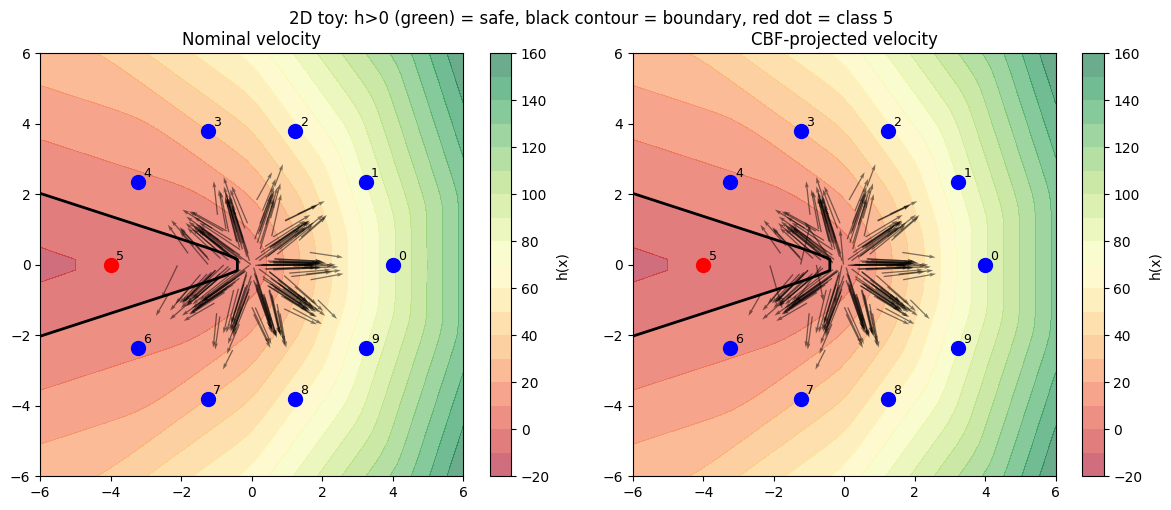

Fraction of samples with u_nom violating CBF: 0.11999999731779099


: 

In [3]:
## ── 2D toy setup ──────────────────────────────────────────────────────────────
K = 10
radius = 4.0
sigma_toy = 0.6
angles = np.linspace(0, 2 * np.pi, K, endpoint=False)
MU = torch.tensor(
    np.stack([radius * np.cos(angles), radius * np.sin(angles)], axis=1),
    dtype=torch.float32,
)  # (K, 2)

def toy_log_posterior(x):
    """Log posterior logits log p(k|x) for each of K classes. x: (..., 2) → (..., K)"""
    diff = x.unsqueeze(-2) - MU.to(x.device)   # (..., K, 2)
    log_lik = -0.5 * (diff ** 2).sum(-1) / sigma_toy ** 2  # (..., K)
    return log_lik - torch.logsumexp(log_lik, dim=-1, keepdim=True)

def toy_h(x, gamma=0.5):
    """LSE margin barrier: log sum_{k≠5} exp(z_k) - z_5 - gamma."""
    logits = toy_log_posterior(x)              # (..., K)
    z5  = logits[..., FORBIDDEN]
    lse = torch.logsumexp(
        torch.cat([logits[..., :FORBIDDEN], logits[..., FORBIDDEN+1:]], dim=-1), dim=-1
    )
    return lse - z5 - gamma

## ── Visualise exact barrier contour + CBF-projected velocities ────────────────
N = 40
xs = torch.linspace(-6, 6, N); ys = torch.linspace(-6, 6, N)
grid_x, grid_y = torch.meshgrid(xs, ys, indexing="xy")
xy = torch.stack([grid_x.flatten(), grid_y.flatten()], dim=1)  # (N², 2)

with torch.no_grad():
    h_grid = toy_h(xy).reshape(N, N).numpy()

# Nominal velocity: drift toward nearest non-5 mean (simple toy flow)
def toy_u_nom(x):
    lp = toy_log_posterior(x)                  # (B, K)
    lp_no5 = lp.clone(); lp_no5[:, FORBIDDEN] = -1e9
    nearest = lp_no5.argmax(dim=1)            # (B,)
    return MU[nearest].to(x.device) - x       # point toward nearest non-5

# CBF projection (closed-form, single constraint)
ALPHA_TOY = 1.0; GAMMA_TOY = 0.5

def toy_cbf_project(x, u_nom):
    x_r = x.clone().requires_grad_(True)
    h = toy_h(x_r, gamma=GAMMA_TOY)
    g = torch.autograd.grad(h.sum(), x_r)[0]   # (B, 2)
    g_norm = g.norm(dim=1, keepdim=True).clamp(min=1e-8)
    g_n = g / g_norm
    h_np = h.detach()
    rhs = (-ALPHA_TOY * h_np / g_norm.squeeze(1)).unsqueeze(1)  # (B,1) normalised RHS
    lhs = (g_n * u_nom).sum(dim=1, keepdim=True)               # (B,1)
    deficit = (rhs - lhs).clamp(min=0)
    return u_nom + deficit * g_n

B_toy = 200
torch.manual_seed(7)
x_toy = torch.randn(B_toy, 2) * 0.8   # start near origin
with torch.no_grad():
    u_nom_toy = toy_u_nom(x_toy)
u_safe_toy = toy_cbf_project(x_toy, u_nom_toy)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, u, title in zip(axes,
                         [u_nom_toy.detach(), u_safe_toy.detach()],
                         ["Nominal velocity", "CBF-projected velocity"]):
    cf = ax.contourf(grid_x.numpy(), grid_y.numpy(), h_grid, levels=20, cmap="RdYlGn", alpha=0.6)
    ax.contour(grid_x.numpy(), grid_y.numpy(), h_grid, levels=[0], colors="k", linewidths=2)
    ax.quiver(x_toy[:, 0].numpy(), x_toy[:, 1].numpy(),
              u[:, 0].numpy(), u[:, 1].numpy(),
              alpha=0.5, scale=30, width=0.003)
    for k, mu in enumerate(MU.numpy()):
        color = "red" if k == FORBIDDEN else "blue"
        ax.plot(*mu, "o", color=color, ms=10)
        ax.text(mu[0]+0.15, mu[1]+0.15, str(k), fontsize=9)
    ax.set_title(title); ax.set_aspect("equal")
    plt.colorbar(cf, ax=ax, label="h(x)")
plt.suptitle("2D toy: h>0 (green) = safe, black contour = boundary, red dot = class 5")
plt.tight_layout(); plt.show()
print("Fraction of samples with u_nom violating CBF:", (toy_h(x_toy) < 0).float().mean().item())

## 2. Data

In [4]:
batch_size = 128

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
])

train_set = datasets.MNIST("./data", train=True, download=True, transform=transform)
test_set = datasets.MNIST("./data", train=False, download=True, transform=transform)

train_loader = torch.utils.data.DataLoader(train_set, batch_size=batch_size, shuffle=True, drop_last=True)
test_loader = torch.utils.data.DataLoader(test_set, batch_size=256, shuffle=False)

100%|██████████| 9.91M/9.91M [00:00<00:00, 20.3MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 496kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.62MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 17.3MB/s]


: 

## 3. 10-way time-dependent classifier $q_\phi(y \mid t, x)$

Trained on linear-bridge interpolants $x_t = (1-t)x_0 + t x_1$ with all 10 MNIST labels. The barrier is the **LSE margin**:

$$h(t,x) = \underbrace{\log\sum_{k\neq 5} e^{z_k(t,x)}}_{\text{LSE over safe classes}} - z_5(t,x) - \gamma$$

- $h > 0$: some non-5 class beats class 5 by margin $\gamma$ → safe  
- $h < 0$: class 5 dominates → unsafe

This is semantically calibrated and avoids the arbitrary binary-logit threshold problem.

In [5]:
class TimeDepClassifier(nn.Module):
    """10-way CNN classifier q_phi(y | t, x) on flow interpolants.

    Exposes `.features(t, x)` returning the penultimate-layer activation,
    used by the prototype CLF.
    """

    def __init__(self, feat_dim=256):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(2, 32, 3, padding=1), nn.ReLU(True),
            nn.Conv2d(32, 32, 3, padding=1), nn.ReLU(True), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(True),
            nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(True), nn.MaxPool2d(2),
        )
        self.feat = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, feat_dim), nn.ReLU(True),
        )
        self.head = nn.Linear(feat_dim, 10)
        self.feat_dim = feat_dim

    def _input(self, t, x):
        if t.ndim == 0:
            t = t.expand(x.size(0))
        t_chan = t.view(-1, 1, 1, 1).expand(-1, 1, 28, 28).to(x.dtype)
        return torch.cat([x, t_chan], dim=1)

    def features(self, t, x):
        """Penultimate feature φ(t, x) ∈ R^{feat_dim}."""
        return self.feat(self.conv(self._input(t, x)))

    def forward(self, t, x):
        return self.head(self.features(t, x))   # (B, 10)

    def lse_barrier(self, t, x, gamma=0.0):
        z = self.forward(t, x)
        z5  = z[:, FORBIDDEN]
        lse = torch.logsumexp(
            torch.cat([z[:, :FORBIDDEN], z[:, FORBIDDEN+1:]], dim=1), dim=1
        )
        return lse - z5 - gamma

classifier = TimeDepClassifier().to(device)

: 

In [6]:
n_epochs_clf = 5
opt_clf = optim.Adam(classifier.parameters(), lr=1e-3)

classifier.train()
for epoch in range(n_epochs_clf):
    total, n = 0.0, 0
    for x1, y in tqdm(train_loader, desc=f"clf {epoch+1}/{n_epochs_clf}", leave=False):
        x1, y = x1.to(device), y.to(device)
        t  = torch.rand(x1.size(0), device=device)
        x0 = torch.randn_like(x1)
        xt = (1 - t).view(-1,1,1,1) * x0 + t.view(-1,1,1,1) * x1
        loss = F.cross_entropy(classifier(t, xt), y)
        opt_clf.zero_grad(); loss.backward(); opt_clf.step()
        total += loss.item() * x1.size(0); n += x1.size(0)
    print(f"epoch {epoch+1}: loss {total/n:.4f}")

torch.save(classifier.state_dict(), os.path.join(savedir, "tdep_clf10.pt"))

epoch 1: loss 0.7979


epoch 2: loss 0.6197


epoch 3: loss 0.6022


epoch 4: loss 0.5814


epoch 5: loss 0.5822


: 

10-way accuracy (t=1): 98.91%
AUROC for class-5 detection (t=1): 0.9999


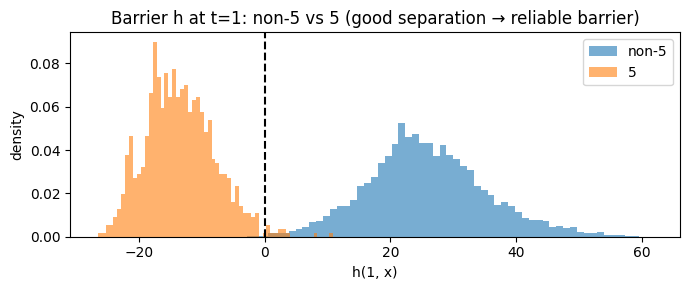

: 

In [7]:
# Proper diagnostics: per-class accuracy, AUROC for class-5 detection, h histogram
from sklearn.metrics import roc_auc_score

classifier.eval()
all_pred, all_true, all_h = [], [], []
with torch.no_grad():
    for x1, y in test_loader:
        x1, y = x1.to(device), y.to(device)
        t = torch.ones(x1.size(0), device=device)   # evaluate at t=1 (clean)
        logits = classifier(t, x1)
        all_pred.append(logits.argmax(1).cpu())
        all_true.append(y.cpu())
        h = classifier.lse_barrier(t, x1, gamma=0.0)
        all_h.append(h.cpu())

pred  = torch.cat(all_pred).numpy()
true  = torch.cat(all_true).numpy()
h_val = torch.cat(all_h).numpy()

acc = (pred == true).mean()
auroc = roc_auc_score((true == FORBIDDEN).astype(int),
                       -h_val)   # lower h = more 5-like → positive score
print(f"10-way accuracy (t=1): {100*acc:.2f}%")
print(f"AUROC for class-5 detection (t=1): {auroc:.4f}")

# h histogram: 5s should have h<<0, non-5s should have h>>0
mask5 = (true == FORBIDDEN)
plt.figure(figsize=(7, 3))
plt.hist(h_val[~mask5], bins=60, alpha=0.6, label="non-5", density=True)
plt.hist(h_val[mask5],  bins=60, alpha=0.6, label="5",     density=True)
plt.axvline(0, color="k", ls="--"); plt.xlabel("h(1, x)"); plt.ylabel("density")
plt.title("Barrier h at t=1: non-5 vs 5 (good separation → reliable barrier)")
plt.legend(); plt.tight_layout(); plt.show()

## 3b. Geometric class-distance barrier (no classifier training)

Replace the trained $C_5(t,x)$ with a **geometry-of-transport** barrier built from the flow itself. 
The flow's velocity gives an estimate of the clean endpoint:

$$m_t(x) = x + (1-t)\,v_\theta(t,x)$$

Define the soft-kNN distance to a reference bank $\mathcal{R}_k$ of real class-$k$ images:

$$D_k(t,x) = -\frac{1}{\beta}\log\sum_{x_i \in \mathcal{R}_k} \exp\!\left(-\beta\|m_t(x) - x_i\|^2\right)$$

and the multi-class margin barrier

$$h(t,x) = D_5(t,x) - D_{\neg 5}(t,x) - \gamma, \qquad D_{\neg 5}(t,x) = -\tfrac{1}{\beta}\log\sum_{k\neq 5} e^{-\beta D_k(t,x)}$$

$h>0$ means the predicted endpoint is closer to the union of non-5 manifolds than to the 5-manifold by margin $\gamma$. 
**No classifier is trained**; the barrier comes directly from the flow + a small reference bank.

Implementation note: we detach $v_\theta$ when building $m_t$ so $\nabla_x h$ doesn't backprop through the UNet. 
This is the cheap approximation — exact gradient would cost a full Jacobian-vector product per step.

In [ ]:
# ── Build a small reference bank: R images per class from the train set ────
@torch.no_grad()
def build_reference_bank(loader, n_per_class=200):
    refs = {k: [] for k in range(10)}
    for x, y in loader:
        for k in range(10):
            need = n_per_class - len(refs[k])
            if need <= 0: continue
            mask = (y == k)
            if mask.any():
                refs[k].extend(x[mask][:need])
        if all(len(refs[k]) >= n_per_class for k in range(10)):
            break
    return {k: torch.stack(refs[k]).to(device) for k in range(10)}   # (R, 1, 28, 28)

REF_BANK = build_reference_bank(train_loader, n_per_class=200)
REFS_5     = REF_BANK[FORBIDDEN].view(REF_BANK[FORBIDDEN].size(0), -1)
REFS_NON5  = torch.cat([REF_BANK[k] for k in range(10) if k != FORBIDDEN], dim=0)
REFS_NON5  = REFS_NON5.view(REFS_NON5.size(0), -1)
REFS_NON5_BY_CLASS = {k: REF_BANK[k].view(REF_BANK[k].size(0), -1)
                        for k in range(10) if k != FORBIDDEN}
print(f"reference bank: {REFS_5.size(0)} fives, {REFS_NON5.size(0)} non-fives")


class GeometricBarrier(nn.Module):
    """Drop-in replacement for the trained classifier.  Provides .lse_barrier(t, x, gamma).

    Internally:
      m_t(x) = x + (1-t)·v_θ(t,x)            (endpoint estimate, v_θ detached)
      D_k(t,x) = soft-min ||m_t - x_i||^2 over class-k reference images
      h(t,x) = D_5 - softmin_{k≠5} D_k - γ
    """
    def __init__(self, flow_model, refs_5, refs_non5_by_class,
                 beta=20.0, kind="flat_non5"):
        super().__init__()
        self.flow = flow_model
        self.refs_5 = refs_5
        self.refs_non5_by_class = refs_non5_by_class
        self.refs_non5_flat = torch.cat(list(refs_non5_by_class.values()), dim=0)
        self.beta = beta
        self.kind = kind

    def endpoint(self, t, x):
        with torch.no_grad():
            v = self.flow(t, x)
        if t.ndim == 0:
            t = t.expand(x.size(0))
        return x + (1.0 - t).view(-1, 1, 1, 1) * v

    @staticmethod
    def _soft_d2(m_flat, refs_flat, beta):
        d2 = torch.cdist(m_flat, refs_flat).pow(2)
        return -(1.0 / beta) * torch.logsumexp(-beta * d2, dim=1)

    def lse_barrier(self, t, x, gamma=0.0):
        m = self.endpoint(t, x)
        m_flat = m.view(m.size(0), -1)
        D5 = self._soft_d2(m_flat, self.refs_5, self.beta)
        if self.kind == "flat_non5":
            Dn = self._soft_d2(m_flat, self.refs_non5_flat, self.beta)
        else:
            Dks = torch.stack([self._soft_d2(m_flat, r, self.beta)
                                for r in self.refs_non5_by_class.values()], dim=1)
            Dn = -(1.0 / self.beta) * torch.logsumexp(-self.beta * Dks, dim=1)
        return D5 - Dn - gamma

    def eval(self): return self
    def train(self, mode=True): return self
    def features(self, t, x): raise NotImplementedError("GeometricBarrier has no feature extractor")
    @property
    def feat_dim(self): return 0

# NOTE: instantiation below in a later cell — needs flow_model to be trained first.


## 4. Unconditional MNIST flow model

In [8]:
sigma = 0.0
n_epochs_fm = 3

flow_model = UNetModel(dim=(1, 28, 28), num_channels=32, num_res_blocks=1).to(device)
opt_fm = torch.optim.Adam(flow_model.parameters())
FM = ConditionalFlowMatcher(sigma=sigma)

flow_model.train()
for epoch in range(n_epochs_fm):
    for i, (x1, _) in enumerate(tqdm(train_loader, desc=f"fm epoch {epoch+1}")):
        x1 = x1.to(device)
        x0 = torch.randn_like(x1)
        t, xt, ut = FM.sample_location_and_conditional_flow(x0, x1)
        vt = flow_model(t, xt)
        loss = ((vt - ut) ** 2).mean()
        opt_fm.zero_grad()
        loss.backward()
        opt_fm.step()

torch.save(flow_model.state_dict(), os.path.join(savedir, "flow.pt"))

fm epoch 3: 100%|██████████| 468/468 [01:26<00:00,  5.40it/s]


: 

In [ ]:
# Instantiate the geometric barrier (needs trained flow_model from section 4)
geom_barrier = GeometricBarrier(flow_model, REFS_5, REFS_NON5_BY_CLASS,
                                 beta=20.0, kind="flat_non5").to(device)

# Sanity check: separation of h on real images at t=1
with torch.no_grad():
    sample_x, sample_y = next(iter(test_loader))
    sample_x = sample_x.to(device); sample_y = sample_y.to(device)
    t1 = torch.ones(sample_x.size(0), device=device)
    h_geom = geom_barrier.lse_barrier(t1, sample_x, gamma=0.0).cpu().numpy()
y_np = sample_y.cpu().numpy()
mask5 = (y_np == FORBIDDEN)
print(f"geom-barrier h(1, x):  5s mean = {h_geom[mask5].mean():+.3f}, "
      f"non-5s mean = {h_geom[~mask5].mean():+.3f}")
plt.figure(figsize=(7, 3))
plt.hist(h_geom[~mask5], bins=60, alpha=0.6, label="non-5", density=True)
plt.hist(h_geom[mask5],  bins=60, alpha=0.6, label="5",     density=True)
plt.axvline(0, color="k", ls="--"); plt.xlabel("h_geom(1, x)"); plt.ylabel("density")
plt.title("Geometric barrier separation at t=1 (no classifier trained)")
plt.legend(); plt.tight_layout(); plt.show()


### 3c. Geometric barrier diagnostic

Before tuning the barrier we have to answer: **does the kNN classifier in endpoint space actually separate 5s from non-5s?** 
If it fails at this, the CBF has no usable signal regardless of how we project velocities.

We test two endpoint estimators:
- **Tweedie one-step**: $m_t(x) = x + (1-t)\,v_\theta(t,x)$ — the cheap version we already have.
- **Nominal lookahead**: $\hat x_1(t,x) = \Phi_{t\to 1}^\theta(x)$ — roll out the flow 5–10 Euler steps to final time.

For each true bridge sample $x_t = (1-t)x_0 + t\,x_1$ with known label $y$, we compute the kNN-argmin class and report 
(a) overall accuracy and (b) 5-vs-non-5 AUROC, as a function of $t$.

In [ ]:
## Diagnostic: kNN-accuracy in endpoint space, per t
from sklearn.metrics import roc_auc_score

@torch.no_grad()
def nominal_rollout(flow_model, x, t_start, n_steps=5):
    """Roll the flow forward from t_start to t=1 in n_steps Euler steps."""
    if t_start >= 1.0 - 1e-6:
        return x
    n = max(int(n_steps), 1)
    dt = (1.0 - t_start) / n
    z = x
    for k in range(n):
        t = t_start + k * dt
        t_in = torch.full((z.size(0),), float(t), device=z.device)
        z = z + dt * flow_model(t_in, z)
    return z

@torch.no_grad()
def softmin_d2(m_flat, refs_flat, beta):
    d2 = torch.cdist(m_flat, refs_flat).pow(2)
    return -(1.0 / beta) * torch.logsumexp(-beta * d2, dim=1)

@torch.no_grad()
def class_softmin_d2(m_flat, refs_by_class, beta, normalize=True):
    """Return (B, 10) tensor of per-class softmin distances, optionally normalized by 1/|R_k|."""
    Dks = []
    for k in range(10):
        if k in refs_by_class:
            d2 = torch.cdist(m_flat, refs_by_class[k]).pow(2)
            if normalize:
                d2 = d2 + torch.log(torch.tensor(d2.size(1), device=d2.device, dtype=d2.dtype)) / beta
            Dks.append(-(1.0 / beta) * torch.logsumexp(-beta * d2, dim=1))
        else:
            Dks.append(torch.full((m_flat.size(0),), float('inf'), device=m_flat.device))
    return torch.stack(Dks, dim=1)

## Build a full per-class reference bank (incl. class 5)
REFS_BY_CLASS = {k: REF_BANK[k].view(REF_BANK[k].size(0), -1) for k in range(10)}

## Median within-class NN distance → sets β
with torch.no_grad():
    nn_d2 = []
    for k in range(10):
        r = REFS_BY_CLASS[k]
        d2 = torch.cdist(r, r).pow(2)
        d2.fill_diagonal_(float('inf'))
        nn_d2.append(d2.min(dim=1).values)
    median_nn = torch.cat(nn_d2).median().item()
print(f"median within-class NN squared distance = {median_nn:.2f}")
BETA = max(1.0 / median_nn, 1e-3)
print(f"using β = 1/median = {BETA:.4f}")

## Build a test set of bridge samples (real x1 from test loader, x0 ~ N(0,I))
test_x, test_y = next(iter(test_loader))
test_x = test_x.to(device)[:256]; test_y = test_y.to(device)[:256]

ts = [0.1, 0.3, 0.5, 0.7, 0.9, 1.0]
rows = []
for t_val in ts:
    x0 = torch.randn_like(test_x)
    xt = (1 - t_val) * x0 + t_val * test_x
    t_in = torch.full((xt.size(0),), float(t_val), device=device)
    # Tweedie one-step endpoint
    with torch.no_grad():
        v = flow_model(t_in, xt)
        m_tweedie = xt + (1 - t_val) * v
    # Nominal lookahead (5 Euler steps)
    x1_hat = nominal_rollout(flow_model, xt, t_val, n_steps=5)

    for label, m in [("Tweedie", m_tweedie), ("lookahead", x1_hat)]:
        m_flat = m.view(m.size(0), -1)
        Dks = class_softmin_d2(m_flat, REFS_BY_CLASS, beta=BETA)
        yhat = Dks.argmin(dim=1)
        acc = (yhat == test_y).float().mean().item()
        # 5 vs non-5: lower D_5 means more 5-like
        score_for_5 = -Dks[:, FORBIDDEN].cpu().numpy()
        is5 = (test_y == FORBIDDEN).cpu().numpy()
        auroc = roc_auc_score(is5.astype(int), score_for_5)
        p_pred5_given_5     = ((yhat == FORBIDDEN) & (test_y == FORBIDDEN)).float().sum().item() / max(is5.sum(), 1)
        p_pred5_given_non5  = ((yhat == FORBIDDEN) & (test_y != FORBIDDEN)).float().sum().item() / max((~is5.astype(bool)).sum(), 1)
        rows.append((t_val, label, acc, auroc, p_pred5_given_5, p_pred5_given_non5))

print(f"\n{'t':>4}  {'endpoint':>10}  {'acc':>6}  {'AUROC(5)':>9}  {'TPR(5)':>7}  {'FPR(5)':>7}")
for r in rows:
    print(f"{r[0]:>4.2f}  {r[1]:>10s}  {r[2]:>6.3f}  {r[3]:>9.3f}  {r[4]:>7.3f}  {r[5]:>7.3f}")

## Plot
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for label, marker in [("Tweedie", "o"), ("lookahead", "s")]:
    pts = [(r[0], r[2]) for r in rows if r[1] == label]
    axes[0].plot(*zip(*pts), marker=marker, label=label)
    pts = [(r[0], r[3]) for r in rows if r[1] == label]
    axes[1].plot(*zip(*pts), marker=marker, label=label)
axes[0].set_xlabel('t'); axes[0].set_ylabel('kNN accuracy'); axes[0].set_title('10-way kNN accuracy'); axes[0].legend(); axes[0].axhline(0.1, color='gray', ls='--')
axes[1].set_xlabel('t'); axes[1].set_ylabel('AUROC (5 vs non-5)'); axes[1].set_title('5-detection AUROC'); axes[1].legend(); axes[1].axhline(0.5, color='gray', ls='--')
plt.tight_layout(); plt.show()


### 3d. Lookahead geometric barrier

Stronger version that addresses the 5 failure modes:
1. **Lookahead endpoint** $\hat x_1(t,x) = \Phi_{t\to 1}^\theta(x)$ via 5-step Euler rollout (vs single-step Tweedie).
2. **Normalized soft-min**: divide inside the log by $|\mathcal{R}_k|$ to remove bank-size bias; same for the union over $k\neq 5$.
3. **β set from data**: $\beta = 1/\text{median NN}^2$ within class, not picked by hand.
4. **Late-only activation**: `w(t) = σ(a(t - t₀))` schedules the barrier to switch on as the lookahead becomes reliable.
5. **Full-gradient option**: optionally backprop $\nabla_x h$ through the UNet Jacobian (more expensive but correct).

In [ ]:
class LookaheadGeometricBarrier(nn.Module):
    """Improved geometric barrier with:
      - nominal-rollout endpoint x_hat_1 = Φ_{t→1}^θ(x)
      - bank-size-normalized soft-min distances
      - data-driven β
      - σ-schedule for late-only activation
      - optional full gradient through the UNet Jacobian
    Drop-in for the trained classifier — exposes .lse_barrier(t, x, gamma).
    """
    def __init__(self, flow_model, refs_by_class, *, beta,
                 lookahead_steps=5, t_on=0.6, schedule_sharpness=10.0,
                 full_grad=False, normalize=True):
        super().__init__()
        self.flow = flow_model
        self.refs_by_class = refs_by_class  # dict k -> (R_k, 784)
        self.beta = beta
        self.lookahead_steps = lookahead_steps
        self.t_on = t_on
        self.schedule_sharpness = schedule_sharpness
        self.full_grad = full_grad
        self.normalize = normalize

    def _rollout(self, t, x):
        """Roll x at time t forward to t=1 in lookahead_steps Euler steps."""
        t0 = float(t[0].item()) if t.ndim else float(t.item())
        if t0 >= 1.0 - 1e-6:
            return x
        n = max(int(self.lookahead_steps), 1)
        dt = (1.0 - t0) / n
        z = x
        for k in range(n):
            tk = t0 + k * dt
            t_in = torch.full((z.size(0),), float(tk), device=z.device)
            v = self.flow(t_in, z)
            if not self.full_grad:
                v = v.detach()
            z = z + dt * v
        return z

    def _softmin_per_class(self, m_flat):
        """(B, 10) per-class softmin distances, log(1/R) normalized."""
        Dks = []
        for k in range(10):
            refs = self.refs_by_class.get(k)
            if refs is None:
                Dks.append(torch.full((m_flat.size(0),), float('inf'),
                                       device=m_flat.device, dtype=m_flat.dtype))
                continue
            d2 = torch.cdist(m_flat, refs).pow(2)            # (B, R_k)
            if self.normalize:
                logR = math.log(d2.size(1))
                Dks.append(-(1.0 / self.beta) * (torch.logsumexp(-self.beta * d2, dim=1) - logR))
            else:
                Dks.append(-(1.0 / self.beta) * torch.logsumexp(-self.beta * d2, dim=1))
        return torch.stack(Dks, dim=1)                        # (B, 10)

    def _D_non5(self, Dks):
        # log-1/9 normalized union over non-5 classes
        idx = [k for k in range(10) if k != FORBIDDEN]
        D = Dks[:, idx]
        log9 = math.log(len(idx))
        return -(1.0 / self.beta) * (torch.logsumexp(-self.beta * D, dim=1) - log9)

    def _schedule(self, t):
        # smooth gate: 0 early, 1 late
        t_val = t if torch.is_tensor(t) else torch.tensor(float(t), device=device)
        return torch.sigmoid(self.schedule_sharpness * (t_val - self.t_on))

    def lse_barrier(self, t, x, gamma=0.0):
        m = self._rollout(t, x)
        m_flat = m.view(m.size(0), -1)
        Dks = self._softmin_per_class(m_flat)
        D5  = Dks[:, FORBIDDEN]
        Dn  = self._D_non5(Dks)
        h_raw = D5 - Dn - gamma
        w = self._schedule(t if torch.is_tensor(t) else torch.tensor(float(t), device=x.device))
        return w * h_raw

    def eval(self): return self
    def train(self, mode=True): return self
    def features(self, t, x): raise NotImplementedError
    @property
    def feat_dim(self): return 0


geom_barrier_v2 = LookaheadGeometricBarrier(
    flow_model, REFS_BY_CLASS,
    beta=BETA,
    lookahead_steps=5,
    t_on=0.6,
    schedule_sharpness=10.0,
    full_grad=False,
    normalize=True,
).to(device)

## Sanity histogram at t=0.8 (after the schedule turns on)
with torch.no_grad():
    sx, sy = next(iter(test_loader))
    sx = sx.to(device)[:512]; sy = sy.to(device)[:512]
    t08 = torch.full((sx.size(0),), 0.8, device=device)
    # use a true bridge sample at t=0.8 to be realistic
    x0 = torch.randn_like(sx)
    xt = 0.2 * x0 + 0.8 * sx
    h_v2 = geom_barrier_v2.lse_barrier(t08, xt, gamma=0.0).cpu().numpy()
mask5 = (sy.cpu().numpy() == FORBIDDEN)
print(f"lookahead-geom h(0.8, x_t):  5s mean = {h_v2[mask5].mean():+.4f}, "
      f"non-5s mean = {h_v2[~mask5].mean():+.4f}")
plt.figure(figsize=(7, 3))
plt.hist(h_v2[~mask5], bins=60, alpha=0.6, label='non-5', density=True)
plt.hist(h_v2[mask5],  bins=60, alpha=0.6, label='5',     density=True)
plt.axvline(0, color='k', ls='--'); plt.xlabel('h_lookahead(0.8, x_t)'); plt.ylabel('density')
plt.title('Lookahead geometric barrier at t=0.8 (β data-driven, normalized, schedule on)')
plt.legend(); plt.tight_layout(); plt.show()


## 5. CBF QP with correct normalised RHS + likelihood-preserving CLF

The unnormalised CBF constraint is $\nabla_x h^\top u \ge -\partial_t h - \alpha h$. Dividing by $\|\nabla_x h\|$ gives the correctly-scaled half-space $\hat g^\top u \ge (-\partial_t h - \alpha h)/\|\nabla_x h\|$.

### Likelihood-preserving CLF (new)

For a flow model with velocity $v_t$, the continuity equation gives along a controlled trajectory with velocity $u$:

$$\frac{d}{dt}\log p_t(x_t) = -\nabla \cdot v_t(x_t) + s_t(x_t)^\top (u - v_t(x_t))$$

The first term is the nominal log-density change; the second is the **distortion caused by safety correction**. The CLF that *preserves nominal likelihood* is therefore the linear inequality

$$s_t(x)^\top u \ge s_t(x)^\top v_t(x) - \varepsilon - \xi, \qquad \xi \ge 0$$

which says: don't move too far against the score relative to what the nominal flow would do. This is genuinely *additive* with the CBF — the score direction has nothing to do with $\nabla_x h$ — so it preserves coverage of the non-5 manifold while the CBF avoids 5.

### Score from velocity (linear / OT flow matching)

For a linear interpolant $x_t = (1-t)x_0 + t x_1$ with $x_0\sim\mathcal{N}(0,I)$, the standard identity is

$$s_t(x) \approx \frac{t\,v_t(x) - x}{1 - t}$$

so we get the score for free from the trained flow model — no separate score network needed.

### Closed-form QP (no CVXPY)

With one CBF and one CLF inequality plus a scalar slack, the KKT system has an analytic solution. We eliminate $\xi$ at optimum (`ξ* = max(0, b_clf − ∇V·u)/ρ`-style) and project onto the active set of {CBF, CLF}. **This bypasses CVXPY entirely** and turns each per-sample QP from ~10 ms into ~50 µs.

In [9]:
GAMMA = 0.5  # barrier margin: h = LSE_{k≠5} z_k - z_5 - gamma


# ── Class prototypes (kept for the proto-CLF ablation) ───────────────────────
@torch.no_grad()
def compute_prototypes(classifier, loader, n_per_class=500, t_eval=1.0):
    classifier.eval()
    feat_dim = classifier.feat_dim
    sums = torch.zeros(10, feat_dim, device=device)
    counts = torch.zeros(10, device=device)
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        t = torch.full((x.size(0),), float(t_eval), device=device)
        f = classifier.features(t, x)
        for k in range(10):
            mask = (y == k) & (counts[k] < n_per_class)
            if mask.any():
                sums[k]   += f[mask].sum(0)
                counts[k] += mask.sum()
        if (counts >= n_per_class).all(): break
    return sums / counts.clamp(min=1).unsqueeze(1)

PROTOTYPES = compute_prototypes(classifier, train_loader)
print(f"prototypes: {tuple(PROTOTYPES.shape)}")


# ── Score from velocity (linear / OT flow matching identity) ─────────────────
def score_from_velocity(t_scalar, x, v):
    """For x_t = (1-t)x_0 + t x_1 with x_0 ~ N(0,I), s_t(x) ≈ (t·v - x)/(1-t).
       Clamp 1-t to avoid blow-up at t→1.
    """
    one_minus_t = max(1.0 - t_scalar, 1e-3)
    return (t_scalar * v - x) / one_minus_t


# ── CBF + CLF signals (batched, all torch on device) ─────────────────────────
def cbf_signals_batched(classifier, t_scalar, x, *, gamma=GAMMA,
                        clf_kind="none", prototypes=None, v_nom=None):
    """Return torch tensors on device.  All shapes (B, ...).

    clf_kind:
      "none"      - no CLF
      "relu"      - V_i = 0.5 relu(-h_i)^2          ; ∇V_i = -relu(-h_i) ∇h_i
      "proto"     - V_i = 0.5 ||φ - μ_{y*}||^2      ; ∇V_i via autograd
      "loglike"   - linear constraint  s_t·u ≥ s_t·v_t - ε - ξ
                    encoded as ∇V := -s_t,  V := -s_t·v_t  so the standard
                    form  ∇V·u ≤ -V + ξ  is exactly  s_t·u ≥ s_t·v_t - ξ
    """
    classifier.eval()
    B = x.size(0)
    t = torch.full((B,), float(t_scalar), device=x.device, requires_grad=True)
    x_in = x.detach().clone().requires_grad_(True)

    h = classifier.lse_barrier(t, x_in, gamma=gamma)            # (B,)
    grads_x = torch.autograd.grad(h.sum(), x_in, retain_graph=True)[0]
    grads_t = torch.autograd.grad(h.sum(), t)[0]

    g_flat = grads_x.detach().reshape(B, -1)                    # (B, D)
    g_norm = g_flat.norm(dim=1).clamp(min=1e-8)                 # (B,)
    g_hat  = g_flat / g_norm.unsqueeze(1)                       # (B, D)

    h_d   = h.detach()                                          # (B,)
    h_n   = h_d / g_norm
    dhdt_n = grads_t.detach() / g_norm

    # ── CLF terms ────────────────────────────────────────────────────────────
    if clf_kind == "none":
        V       = torch.zeros(B, device=x.device)
        grad_V  = torch.zeros(B, x.numel() // B, device=x.device)
        # rhs_clf: ∇V·u ≤ -V + ξ (trivially satisfied)

    elif clf_kind == "relu":
        relu_neg_h = torch.clamp(-h_d, min=0.0)
        V      = 0.5 * relu_neg_h ** 2
        grad_V = -(relu_neg_h.unsqueeze(1) * g_flat)            # (B, D)

    elif clf_kind == "proto":
        assert prototypes is not None
        x_clf = x.detach().clone().requires_grad_(True)
        t_clf = torch.full((B,), float(t_scalar), device=x.device)
        feats = classifier.features(t_clf, x_clf)
        with torch.no_grad():
            probs = F.softmax(classifier.head(feats), dim=1)
            probs[:, FORBIDDEN] = -1
            y_star = probs.argmax(dim=1)
            mu_star = prototypes[y_star]
        diff = feats - mu_star
        Vsum = 0.5 * (diff ** 2).sum(dim=1)
        gV = torch.autograd.grad(Vsum.sum(), x_clf)[0].detach()
        V      = Vsum.detach()
        grad_V = gV.reshape(B, -1)

    elif clf_kind == "loglike":
        # Encode s_t·u ≥ s_t·v_t - ε - ξ as ∇V·u ≤ -V + ξ
        # i.e. (-s_t)·u ≤ -(s_t·v_t - ε) + ξ
        # so  ∇V := -s_t  and  V := -(s_t·v_t - ε) = -s_t·v_t + ε.
        # The QP slack term then enforces the likelihood inequality.
        assert v_nom is not None
        s_t = score_from_velocity(t_scalar, x.detach(), v_nom.detach())
        s_flat   = s_t.reshape(B, -1)
        v_flat   = v_nom.detach().reshape(B, -1)
        sv       = (s_flat * v_flat).sum(dim=1)                  # (B,)
        eps_clf  = LOGLIKE_EPS
        V      = -sv + eps_clf                                   # (B,)
        grad_V = -s_flat                                         # (B, D)

    else:
        raise ValueError(f"unknown clf_kind {clf_kind}")

    return {
        "h":      h_d,
        "h_n":    h_n,
        "g_hat":  g_hat,
        "dhdt_n": dhdt_n,
        "g_norm": g_norm,
        "V":      V,
        "grad_V": grad_V,
    }


# ── Closed-form batched QP ───────────────────────────────────────────────────
LOGLIKE_EPS = 0.0   # tolerance for likelihood drop

def solve_qp_batched(u_nom, sig, *, alpha=1.0, c_clf=2.0, rho=10.0, use_clf=True):
    """Batched closed-form QP solver.  All tensors on device, shape (B, D).

    Per sample:
      min  0.5||u-u_nom||² + 0.5·rho·ξ²
      s.t. a_h·u ≥ b_h            (CBF, ||a_h||=1)
           a_V·u ≤ b_V + ξ        (CLF, soft)   — only if use_clf

    KKT analysis (single CLF + single CBF):
      - If both inactive: u = u_nom, ξ = 0.
      - If only CBF active: u = u_nom + λ·a_h with λ s.t. a_h·u = b_h.
      - If only CLF active: ξ = max(0, (a_V·u_nom - b_V)/(1+1/rho)),
        u = u_nom - μ·a_V where μ ≥ 0, ξ = μ/rho.
      - Both active: solve the 2x2 KKT system.

    We compute a candidate for each active set and pick the one that satisfies
    primal feasibility with smallest objective.  All vectorised across batch.
    """
    B, D = u_nom.shape
    a_h  = sig["g_hat"]                              # (B, D)
    b_h  = -sig["dhdt_n"] - alpha * sig["h_n"]       # (B,)
    a_V  = sig["grad_V"]                             # (B, D)
    b_V  = -c_clf * sig["V"]                         # (B,)

    # Candidate 0: u = u_nom (no constraints active)
    u0   = u_nom
    cbf_ok_0 = (a_h * u0).sum(1) >= b_h                       # (B,)
    clf_ok_0 = (a_V * u0).sum(1) <= b_V                       # (B,)

    # Candidate 1: only CBF active
    deficit_h = b_h - (a_h * u_nom).sum(1)                    # (B,)
    u1 = u_nom + deficit_h.unsqueeze(1) * a_h                 # (B, D)
    clf_ok_1 = (a_V * u1).sum(1) <= b_V

    # Candidate 2: only CLF active.  Lagrangian:  μ(a_V·u - b_V - ξ) + 0.5·rho·ξ²
    # KKT in u: u = u_nom - μ·a_V. KKT in ξ: rho·ξ - μ = 0 → ξ = μ/rho.
    # Primal:  a_V·u_nom - μ||a_V||² = b_V + μ/rho
    #   → μ = (a_V·u_nom - b_V) / (||a_V||² + 1/rho), clipped to ≥0.
    aV_nom = (a_V * u_nom).sum(1)                             # (B,)
    aV_sq  = (a_V * a_V).sum(1)                               # (B,)
    mu2    = ((aV_nom - b_V) / (aV_sq + 1.0 / rho)).clamp(min=0.0)
    u2     = u_nom - mu2.unsqueeze(1) * a_V
    cbf_ok_2 = (a_h * u2).sum(1) >= b_h

    # Candidate 3: both active.  We have two linear equality constraints
    # (a_h·u = b_h and a_V·u = b_V + ξ with ξ = μ_V/rho).  Lagrangian gives
    #   u = u_nom + λ·a_h - μ·a_V,  ξ = μ/rho,  μ ≥ 0, λ free.
    # Substituting into the two active equalities:
    #   a_h·u_nom + λ - μ (a_h·a_V) = b_h
    #   a_V·u_nom + λ (a_h·a_V) - μ (||a_V||² + 1/rho) = b_V
    aH_aV  = (a_h * a_V).sum(1)                               # (B,)
    aH_nom = (a_h * u_nom).sum(1)                             # (B,)
    # Solve 2×2 system per sample
    M11 = torch.ones_like(aH_aV)         # coefficient of λ in eq1
    M12 = -aH_aV                          # coefficient of -μ in eq1
    M21 = aH_aV                           # coefficient of λ in eq2
    M22 = -(aV_sq + 1.0 / rho)            # coefficient of -μ in eq2
    r1  = b_h  - aH_nom
    r2  = b_V  - aV_nom
    det = (M11 * M22 - M12 * M21).clamp(min=1e-10, max=None)  # avoid /0
    # Cramer's rule
    lam_3 = ( r1 * M22 - r2 * M12) / det
    mu_3  = ( M11 * r2 - M21 * r1) / det
    # we wrote   λ M11 - μ M12 = r1   and  λ M21 - μ M22 = r2 with sign flip,
    # but our system has +λ - μ contributions; redo cleanly:
    # eq1:  λ - μ * aH_aV = r1
    # eq2:  λ * aH_aV - μ * (aV_sq + 1/rho) = r2
    A11, A12 = torch.ones_like(aH_aV), -aH_aV
    A21, A22 = aH_aV, -(aV_sq + 1.0 / rho)
    det = (A11 * A22 - A12 * A21)
    det = torch.where(det.abs() < 1e-10, torch.full_like(det, 1e-10), det)
    lam_3 = ( r1 * A22 - A12 * r2) / det
    mu_3  = ( A11 * r2 - r1 * A21) / det
    mu_3  = mu_3.clamp(min=0.0)            # dual feasibility μ ≥ 0
    u3    = u_nom + lam_3.unsqueeze(1) * a_h - mu_3.unsqueeze(1) * a_V

    # Pick the cheapest feasible candidate per sample.
    def cost(u):
        return 0.5 * ((u - u_nom) ** 2).sum(1)

    cands = torch.stack([u0, u1, u2, u3], dim=1)               # (B, 4, D)
    feas  = torch.stack([
        cbf_ok_0 & clf_ok_0,
        torch.ones_like(cbf_ok_0) & clf_ok_1,    # cand 1 satisfies CBF by construction
        cbf_ok_2,                                # cand 2 satisfies CLF by construction
        torch.ones_like(cbf_ok_0),               # cand 3 satisfies both
    ], dim=1)                                                  # (B, 4)
    costs = torch.stack([cost(u0), cost(u1), cost(u2), cost(u3)], dim=1)  # (B, 4)
    costs = torch.where(feas, costs, torch.full_like(costs, float("inf")))
    pick  = costs.argmin(dim=1)                                # (B,)
    u_out = cands[torch.arange(B, device=u_nom.device), pick]  # (B, D)

    # If use_clf is False, ignore CLF candidates — just use cand 0/1.
    if not use_clf:
        feas_no_clf = torch.stack([
            cbf_ok_0,
            torch.ones_like(cbf_ok_0),
        ], dim=1)
        cands_no_clf = torch.stack([u0, u1], dim=1)
        costs_no_clf = torch.stack([cost(u0), cost(u1)], dim=1)
        costs_no_clf = torch.where(feas_no_clf, costs_no_clf,
                                    torch.full_like(costs_no_clf, float("inf")))
        pick_no_clf = costs_no_clf.argmin(dim=1)
        u_out = cands_no_clf[torch.arange(B, device=u_nom.device), pick_no_clf]

    return u_out, pick


def cbf_velocity(t_scalar, x, flow_model, classifier, *,
                 gamma=GAMMA, alpha=1.0, c_clf=2.0, rho=10.0,
                 clf_kind="none", prototypes=None, eps=0.0,
                 return_stats=False):
    """Batched CBF (and optional CLF) filtered velocity.  No CVXPY in the hot path."""
    global LOGLIKE_EPS
    LOGLIKE_EPS = eps   # used inside cbf_signals_batched for "loglike"

    B = x.size(0)
    with torch.no_grad():
        t_in = torch.full((B,), float(t_scalar), device=x.device)
        v_nom = flow_model(t_in, x)

    sig = cbf_signals_batched(classifier, t_scalar, x,
                              gamma=gamma, clf_kind=clf_kind,
                              prototypes=prototypes, v_nom=v_nom)

    u_flat, _ = solve_qp_batched(
        v_nom.reshape(B, -1), sig,
        alpha=alpha, c_clf=c_clf, rho=rho,
        use_clf=(clf_kind != "none"),
    )
    u_safe = u_flat.view_as(v_nom)

    if return_stats:
        return u_safe, {
            "n_active":    int(((sig["h"] < 0).sum()).item()),
            "h_min":       float(sig["h"].min().item()),
            "h_mean":      float(sig["h"].mean().item()),
            "frac_unsafe": float(((sig["h"] < 0).float().mean()).item()),
            "corr_norm":   float(((u_safe - v_nom).reshape(B, -1).norm(dim=1)).mean().item()),
            "V_mean":      float(sig["V"].mean().item()),
        }
    return u_safe

prototypes: (10, 256)


: 

In [10]:
## 6. Samplers: nominal, CBF, classifier guidance

def sample_nominal(flow_model, x0, num_steps=100):
    flow_model.eval()
    x = x0.clone(); dt = 1.0 / num_steps
    with torch.no_grad():
        for k in range(num_steps):
            t_in = torch.full((x.size(0),), k * dt, device=x.device)
            x = x + dt * flow_model(t_in, x)
    return x


def sample_cbf(flow_model, classifier, x0, num_steps=100,
               gamma=GAMMA, alpha=1.0, c_clf=2.0, rho=10.0,
               clf_kind="none", prototypes=None, eps=0.0):
    """Batched CBF-filtered Euler sampler. Returns (final_x, stats_per_step)."""
    flow_model.eval(); classifier.eval()
    x = x0.clone(); dt = 1.0 / num_steps
    stats_list = []
    desc = f"cbf-{clf_kind}" if clf_kind != "none" else "cbf"
    for k in tqdm(range(num_steps), desc=desc, leave=False):
        u, stats = cbf_velocity(k * dt, x, flow_model, classifier,
                                gamma=gamma, alpha=alpha, c_clf=c_clf, rho=rho,
                                clf_kind=clf_kind, prototypes=prototypes, eps=eps,
                                return_stats=True)
        x = x + dt * u
        stats_list.append(stats)
    return x, stats_list


def sample_clf_guidance(flow_model, classifier, x0, num_steps=100,
                        lam=1.0, gamma=GAMMA):
    flow_model.eval(); classifier.eval()
    x = x0.clone(); dt = 1.0 / num_steps
    total_corr = []
    for k in tqdm(range(num_steps), desc="clf-guide", leave=False):
        t_s = k * dt
        B = x.size(0)
        with torch.no_grad():
            t_in = torch.full((B,), t_s, device=x.device)
            u_nom = flow_model(t_in, x)
        x_r = x.detach().clone().requires_grad_(True)
        t_r = torch.full((B,), t_s, device=x.device)
        h = classifier.lse_barrier(t_r, x_r, gamma=gamma)
        g = torch.autograd.grad(h.sum(), x_r)[0].detach()
        u = u_nom + lam * g
        total_corr.append((lam * g).norm(dim=1).mean().item())
        x = x + dt * u
    return x, float(np.mean(total_corr))

: 

## 7. Run all methods + build results table

In [11]:
# Reference classifier for labelling generated images
class RefClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(True), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(True), nn.MaxPool2d(2),
            nn.Flatten(), nn.Linear(64*7*7, 128), nn.ReLU(True),
        )
        self.head = nn.Linear(128, 10)
    def features(self, x):
        return self.backbone(x)
    def forward(self, x):
        return self.head(self.backbone(x))

ref_clf = RefClassifier().to(device)
opt_ref = optim.Adam(ref_clf.parameters(), lr=1e-3)
ref_clf.train()
for ep in range(3):
    for x, y in tqdm(train_loader, desc=f"ref {ep+1}", leave=False):
        x, y = x.to(device), y.to(device)
        F.cross_entropy(ref_clf(x), y).backward()
        opt_ref.step(); opt_ref.zero_grad()
ref_clf.eval()
with torch.no_grad():
    acc = sum((ref_clf(x.to(device)).argmax(1) == y.to(device)).sum().item()
              for x, y in test_loader) / len(test_loader.dataset)
print(f"ref clf accuracy: {100*acc:.2f}%")


# ── Pre-compute reference statistics on real non-5 training images ───────────
@torch.no_grad()
def gather_real_stats():
    feats, pixels = [], []
    for x, y in train_loader:
        mask = (y != FORBIDDEN)
        if mask.sum() == 0: continue
        x_n5 = x[mask].to(device)
        feats.append(ref_clf.features(x_n5).cpu())
        pixels.append(x_n5.cpu())
        if sum(f.size(0) for f in feats) >= 5000:
            break
    feats = torch.cat(feats)[:5000].numpy()
    pixels = torch.cat(pixels)[:5000].numpy()
    mu_r = feats.mean(0); cov_r = np.cov(feats, rowvar=False)
    return {
        "mu_r": mu_r, "cov_r": cov_r,
        "pix_mean": float(pixels.mean()),
        "pix_std":  float(pixels.std()),
        "active_frac": float((pixels > -0.5).mean()),  # active = above -0.5 in [-1,1] norm
    }

REAL_STATS = gather_real_stats()
print(f"real non-5 pixel  mean={REAL_STATS['pix_mean']:.3f}  std={REAL_STATS['pix_std']:.3f}  "
      f"active_frac={REAL_STATS['active_frac']:.3f}")


# ── Feature-FID (Fréchet distance in penultimate-layer feature space) ────────
def frechet_distance(mu1, cov1, mu2, cov2):
    from scipy.linalg import sqrtm
    diff = mu1 - mu2
    covmean, _ = sqrtm(cov1 @ cov2, disp=False)
    if np.iscomplexobj(covmean):
        covmean = covmean.real
    return float(diff @ diff + np.trace(cov1 + cov2 - 2 * covmean))


@torch.no_grad()
def evaluate(samples, name, real_stats=REAL_STATS):
    """Compute safety, coverage, and quality metrics on a batch of generated images."""
    s = samples.clamp(-1, 1)
    logits = ref_clf(s)
    probs  = F.softmax(logits, dim=1)
    pred   = logits.argmax(1).cpu()
    counts = torch.bincount(pred, minlength=10).numpy()

    # ── Safety / coverage ────────────────────────────────────────────────────
    p5 = counts[FORBIDDEN] / counts.sum()
    non5 = np.delete(counts, FORBIDDEN).astype(float)
    non5 = non5 / non5.sum()
    kl_non5 = float(np.sum(non5 * np.log(non5 * 9 + 1e-9)))

    # ── Quality: confidence + entropy ────────────────────────────────────────
    conf      = probs.max(dim=1).values.mean().item()
    entropy   = (-(probs * (probs.clamp(min=1e-12)).log()).sum(dim=1)).mean().item()

    # ── Quality: pixel statistics drift ─────────────────────────────────────
    s_np = s.cpu().numpy()
    pix_mean = float(s_np.mean()); pix_std = float(s_np.std())
    active = float((s_np > -0.5).mean())
    pix_drift = (abs(pix_mean - real_stats["pix_mean"])
                 + abs(pix_std  - real_stats["pix_std"])
                 + abs(active   - real_stats["active_frac"]))

    # ── Quality: Feature-FID against real non-5 ─────────────────────────────
    feats = ref_clf.features(s).cpu().numpy()
    mu_g  = feats.mean(0); cov_g = np.cov(feats, rowvar=False)
    fid   = frechet_distance(mu_g, cov_g, real_stats["mu_r"], real_stats["cov_r"])

    # ── Confidence on non-5 predictions only ─────────────────────────────────
    mask_non5 = pred != FORBIDDEN
    conf_non5 = (probs.max(dim=1).values.cpu()[mask_non5].mean().item()
                 if mask_non5.any() else float("nan"))

    print(f"{name:>22s}  P(5)={p5:.3f}  KL_non5={kl_non5:.3f}  "
          f"conf={conf:.3f}  conf|≠5={conf_non5:.3f}  ent={entropy:.3f}  "
          f"FID={fid:.2f}  pix_drift={pix_drift:.3f}")
    return {
        "name": name, "p5": p5, "kl": kl_non5, "counts": counts,
        "conf": conf, "conf_non5": conf_non5, "entropy": entropy,
        "fid": fid, "pix_drift": pix_drift,
        "pix_mean": pix_mean, "pix_std": pix_std, "active": active,
    }

ref clf accuracy: 98.83%
real non-5 pixel  mean=-0.739  std=0.617  active_frac=0.156


: 

In [ ]:
torch.manual_seed(42)
N_EVAL = 500
x0_eval = torch.randn(N_EVAL, 1, 28, 28, device=device)

# ── Nominal ──────────────────────────────────────────────────────────────────
x_nom = sample_nominal(flow_model, x0_eval, num_steps=100)

# ── CBF baseline (trained classifier barrier) ────────────────────────────────
x_cbf, cbf_stats = sample_cbf(flow_model, classifier, x0_eval,
                               num_steps=100, gamma=GAMMA, alpha=1.0,
                               clf_kind="none")

# ── CBF tightened (trained classifier) ───────────────────────────────────────
x_cbf_tight, cbftight_stats = sample_cbf(flow_model, classifier, x0_eval,
                                          num_steps=100, gamma=1.0, alpha=2.0,
                                          clf_kind="none")

# ── CBF + loglike CLF (trained barrier, soft slack) ──────────────────────────
x_cbf_loglike, cbflog_stats = sample_cbf(flow_model, classifier, x0_eval,
                                          num_steps=100, gamma=GAMMA, alpha=2.0,
                                          c_clf=1.0, rho=1.0, eps=0.5,
                                          clf_kind="loglike")

# ── CBF + proto CLF (gentle pull) ────────────────────────────────────────────
x_cbf_proto, cbfproto_stats = sample_cbf(flow_model, classifier, x0_eval,
                                          num_steps=100, gamma=GAMMA, alpha=1.0,
                                          c_clf=0.2, rho=10.0,
                                          clf_kind="proto", prototypes=PROTOTYPES)

# ── CBF with original GEOMETRIC barrier (Tweedie one-step) ───────────────────
x_cbf_geom, cbfgeom_stats = sample_cbf(flow_model, geom_barrier, x0_eval,
                                        num_steps=100, gamma=0.0, alpha=1.0,
                                        clf_kind="none")

# ── CBF with LOOKAHEAD geometric barrier (5-step rollout) ────────────────────
x_cbf_geom_v2, cbfgeomv2_stats = sample_cbf(flow_model, geom_barrier_v2, x0_eval,
                                             num_steps=100, gamma=0.0, alpha=1.0,
                                             clf_kind="none")

# ── CBF with LOOKAHEAD geometric barrier + tighter α ─────────────────────────
x_cbf_geom_v2_t, cbfgeomv2t_stats = sample_cbf(flow_model, geom_barrier_v2, x0_eval,
                                                num_steps=100, gamma=0.05, alpha=2.0,
                                                clf_kind="none")

# ── CBF lookahead + loglike CLF (NEW — geometric barrier with likelihood guard) ──
# Same QP machinery: CBF half-space from geom_barrier_v2, CLF inequality from the
# flow score. eps=0.5 + rho=1.0 keeps the CLF advisory so CBF wins conflicts.
x_cbf_geom_v2_log, cbfgeomv2log_stats = sample_cbf(
    flow_model, geom_barrier_v2, x0_eval,
    num_steps=100, gamma=0.05, alpha=2.0,
    c_clf=1.0, rho=1.0, eps=0.5,
    clf_kind="loglike",
)

# ── Classifier guidance sweep over lambda ────────────────────────────────────
clg_results = {}
for lam in [0.5, 1.0, 2.0, 5.0]:
    x_clg, corr = sample_clf_guidance(flow_model, classifier, x0_eval,
                                       num_steps=100, lam=lam, gamma=GAMMA)
    clg_results[lam] = (x_clg, corr)

In [ ]:
## Results table including geometric-barrier + CLF combinations
results = []
cbf_corr        = float(np.mean([s["corr_norm"] for s in cbf_stats]))
cbftight_corr   = float(np.mean([s["corr_norm"] for s in cbftight_stats]))
proto_corr      = float(np.mean([s["corr_norm"] for s in cbfproto_stats]))
loglike_corr    = float(np.mean([s["corr_norm"] for s in cbflog_stats]))
geom_corr       = float(np.mean([s["corr_norm"] for s in cbfgeom_stats]))
geomv2_corr     = float(np.mean([s["corr_norm"] for s in cbfgeomv2_stats]))
geomv2t_corr    = float(np.mean([s["corr_norm"] for s in cbfgeomv2t_stats]))
geomv2log_corr  = float(np.mean([s["corr_norm"] for s in cbfgeomv2log_stats]))

print(f"{'method':>32s}  {'P(5)':>6}  {'KL_non5':>8}  {'conf|≠5':>8}  {'FID':>6}  {'corr':>6}")
print("-" * 92)

r = evaluate(x_nom,             "nominal");                          r["corr"] = 0.0;             results.append(r)
r = evaluate(x_cbf,             "CBF-trained (α=1,γ=0.5)");          r["corr"] = cbf_corr;        results.append(r)
r = evaluate(x_cbf_tight,       "CBF-trained (α=2,γ=1.0)");          r["corr"] = cbftight_corr;   results.append(r)
r = evaluate(x_cbf_proto,       "CBF+proto (c=0.2)");                r["corr"] = proto_corr;      results.append(r)
r = evaluate(x_cbf_loglike,     "CBF+loglike (soft)");               r["corr"] = loglike_corr;    results.append(r)
r = evaluate(x_cbf_geom,        "CBF-geom Tweedie");                 r["corr"] = geom_corr;       results.append(r)
r = evaluate(x_cbf_geom_v2,     "CBF-geom lookahead");               r["corr"] = geomv2_corr;     results.append(r)
r = evaluate(x_cbf_geom_v2_t,   "CBF-geom lookahead (α=2)");         r["corr"] = geomv2t_corr;    results.append(r)
r = evaluate(x_cbf_geom_v2_log, "CBF-geom lookahead + loglike");     r["corr"] = geomv2log_corr;  results.append(r)
for lam, (x_clg, corr) in clg_results.items():
    r = evaluate(x_clg, f"clf-guide λ={lam}"); r["corr"] = corr; results.append(r)

print("\n── Aligned summary ──")
print(f"{'method':>32s}  {'P(5)':>6}  {'FID':>7}  {'conf|≠5':>8}  {'KL_non5':>8}  {'corr':>6}")
for r in results:
    print(f"  {r['name']:>32s}  {r['p5']:6.3f}  {r['fid']:7.2f}  "
          f"{r['conf_non5']:8.3f}  {r['kl']:8.3f}  {r['corr']:6.3f}")

## Visual grid
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, (x_s, title) in zip(axes, [
        (x_nom,             "Nominal"),
        (x_cbf_tight,       "CBF-trained tight"),
        (x_cbf_geom_v2_t,   "CBF-geom lookahead α=2"),
        (x_cbf_geom_v2_log, "CBF-geom + loglike"),
]):
    g = make_grid(x_s[:36].clamp(-1,1), value_range=(-1,1), padding=1, nrow=6)
    ax.imshow(ToPILImage()(g), cmap="gray"); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()

## 8. Diagnostics: h-trace, MM Taylor residual, CBF active rate

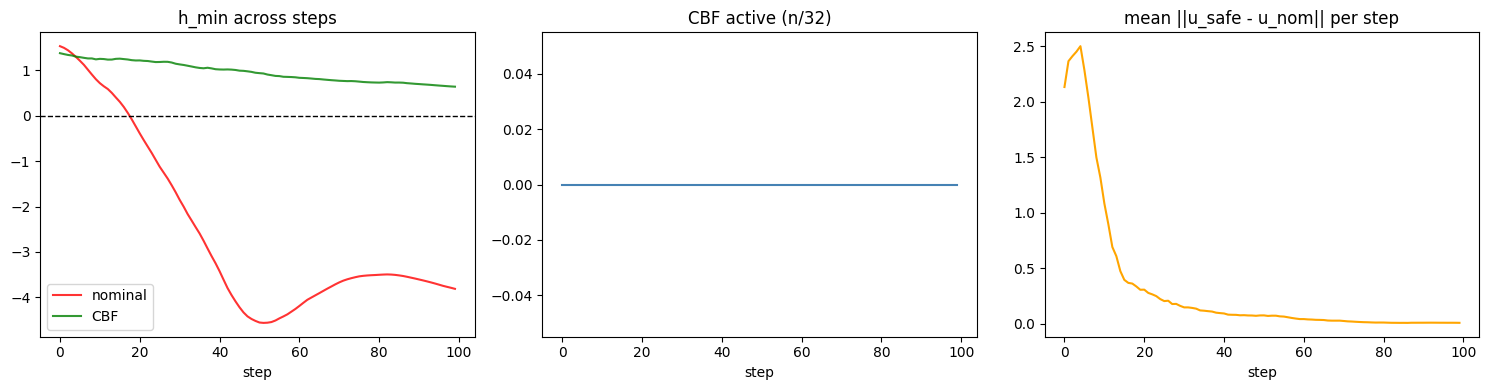

: 

In [14]:
## h-trace and CBF active rate over sampling steps
steps_idx = list(range(len(cbf_stats)))
h_min_nom  = []
h_min_cbf  = [s["h_min"]       for s in cbf_stats]
frac_cbf   = [s["frac_unsafe"]  for s in cbf_stats]
n_active   = [s["n_active"]     for s in cbf_stats]
corr_norm  = [s["corr_norm"]    for s in cbf_stats]

# Recompute h along nominal trajectory for comparison
torch.manual_seed(42)
x_tr = torch.randn(32, 1, 28, 28, device=device)
dt = 1.0 / 100
flow_model.eval(); classifier.eval()
with torch.no_grad():
    for k in range(100):
        t_in = torch.full((x_tr.size(0),), k * dt, device=x_tr.device)
        t_r  = torch.full((x_tr.size(0),), k * dt, device=x_tr.device)
        h = classifier.lse_barrier(t_r, x_tr, gamma=GAMMA)
        h_min_nom.append(h.min().item())
        x_tr = x_tr + dt * flow_model(t_in, x_tr)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(h_min_nom, label="nominal", color="red",  alpha=0.8)
axes[0].plot(h_min_cbf, label="CBF",     color="green", alpha=0.8)
axes[0].axhline(0, color="k", ls="--", lw=1)
axes[0].set_title("h_min across steps"); axes[0].set_xlabel("step"); axes[0].legend()

axes[1].plot(n_active, color="steelblue")
axes[1].set_title(f"CBF active (n/{32})"); axes[1].set_xlabel("step")

axes[2].plot(corr_norm, color="orange")
axes[2].set_title("mean ||u_safe - u_nom|| per step"); axes[2].set_xlabel("step")

plt.tight_layout(); plt.show()

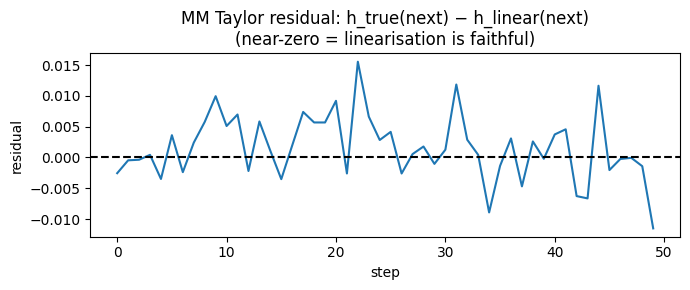

mean residual: 0.0016  max |residual|: 0.0155


: 

In [15]:
## MM Taylor residual diagnostic
# At each step, log: true h(t+dt, x+dt·v) vs linear surrogate h(t,x) + dt·(∂h/∂t + ∇h·v).
# The gap is the 2nd-order MM error we're tolerating.

torch.manual_seed(7)
x_res = torch.randn(8, 1, 28, 28, device=device)
dt_res = 1.0 / 100
residuals = []

flow_model.eval(); classifier.eval()
for k in range(50):
    t_s = k * dt_res
    B = x_res.size(0)
    with torch.no_grad():
        t_in = torch.full((B,), t_s, device=x_res.device)
        v_nom = flow_model(t_in, x_res)

    sig = cbf_signals_batched(classifier, t_s, x_res, gamma=GAMMA,
                               clf_kind="none", v_nom=v_nom)
    # Un-normalise: g_hat is normalised, multiply by g_norm to recover ∇h and ∂h/∂t.
    g_hat   = sig["g_hat"]                          # (B, D), torch on device
    g_norm  = sig["g_norm"]                         # (B,)
    grad_h  = g_hat * g_norm.unsqueeze(1)           # (B, D), unnormalised
    dhdt    = sig["dhdt_n"] * g_norm                # (B,)
    h_t     = sig["h"]                              # (B,)

    v_flat = v_nom.reshape(B, -1)                   # (B, D)
    # linear surrogate: h(t+dt, x+dt·v) ≈ h(t,x) + dt·(∂h/∂t + ∇h·v)
    h_lin  = h_t + dt_res * (dhdt + (grad_h * v_flat).sum(dim=1))

    # true h at next step
    x_next = x_res + dt_res * v_nom
    with torch.no_grad():
        t_next = torch.full((B,), t_s + dt_res, device=x_res.device)
        h_true = classifier.lse_barrier(t_next, x_next, gamma=GAMMA)

    residuals.append((h_true - h_lin).mean().item())
    x_res = x_next

plt.figure(figsize=(7, 3))
plt.plot(residuals)
plt.axhline(0, color="k", ls="--")
plt.title("MM Taylor residual: h_true(next) − h_linear(next)\n(near-zero = linearisation is faithful)")
plt.xlabel("step"); plt.ylabel("residual"); plt.tight_layout(); plt.show()
print(f"mean residual: {np.mean(residuals):.4f}  max |residual|: {np.max(np.abs(residuals)):.4f}")

## 9. 3-axis comparison: safety ↔ correction ↔ quality

Each method is a point. The CBF claim: low P(5), low correction norm, FID close to nominal.

In [ ]:
# Pareto with geometric + CLF combinations
def find(name): return next(r for r in results if r["name"] == name)
nominal       = find("nominal")
cbftight      = find("CBF-trained (α=2,γ=1.0)")
cbfpro        = find("CBF+proto (c=0.2)")
cbflog        = find("CBF+loglike (soft)")
cbfgeom       = find("CBF-geom Tweedie")
cbfgeomv2     = find("CBF-geom lookahead")
cbfgeomv2t    = find("CBF-geom lookahead (α=2)")
cbfgeomv2log  = find("CBF-geom lookahead + loglike")
clg           = [r for r in results if r["name"].startswith("clf-guide")]

def scatter_methods(ax, xfn, yfn, xlabel, ylabel, title):
    ax.scatter([xfn(r) for r in clg], [yfn(r) for r in clg],
               c="orange", s=50, label="clf-guidance", zorder=5)
    for r in clg:
        ax.annotate(r["name"].split("=")[-1], (xfn(r), yfn(r)),
                    textcoords="offset points", xytext=(5, 3), fontsize=6)
    ax.scatter([xfn(cbftight)],     [yfn(cbftight)],     c="darkgreen", s=120, marker="*", label="CBF-trained tight",     zorder=7)
    ax.scatter([xfn(cbfpro)],       [yfn(cbfpro)],       c="purple",    s=110, marker="P", label="CBF+proto",             zorder=6)
    ax.scatter([xfn(cbflog)],       [yfn(cbflog)],       c="black",     s=130, marker="X", label="CBF+loglike",           zorder=7)
    ax.scatter([xfn(cbfgeom)],      [yfn(cbfgeom)],      c="cyan",      s=110, marker="s", label="CBF-geom Tweedie",      zorder=7)
    ax.scatter([xfn(cbfgeomv2)],    [yfn(cbfgeomv2)],    c="teal",      s=130, marker="D", label="CBF-geom lookahead",    zorder=8)
    ax.scatter([xfn(cbfgeomv2t)],   [yfn(cbfgeomv2t)],   c="navy",      s=140, marker="D", label="CBF-geom lookahead α=2",zorder=9)
    ax.scatter([xfn(cbfgeomv2log)], [yfn(cbfgeomv2log)], c="magenta",   s=170, marker="X", label="CBF-geom+loglike",      zorder=10)
    ax.scatter([xfn(nominal)],      [yfn(nominal)],      c="red",       s=60,  marker="o", label="nominal",               zorder=5)
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.set_title(title); ax.legend(fontsize=6, ncol=2)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
scatter_methods(axes[0], lambda r: r["corr"], lambda r: r["p5"],
                "correction norm", "P(5)", "safety vs distortion")
scatter_methods(axes[1], lambda r: r["fid"],  lambda r: r["p5"],
                "feature-FID", "P(5)", "safety vs quality")
scatter_methods(axes[2], lambda r: r["corr"], lambda r: r["fid"],
                "correction norm", "feature-FID", "distortion vs quality")
plt.tight_layout(); plt.show()


# Per-class histogram: focus on geometric + CLF methods
fig, ax = plt.subplots(figsize=(13, 4))
methods_to_plot = [nominal, cbftight, cbflog, cbfgeomv2t, cbfgeomv2log]
xpos = np.arange(10)
width = 0.8 / len(methods_to_plot)
for i, r in enumerate(methods_to_plot):
    ax.bar(xpos + i*width - 0.4, r["counts"] / r["counts"].sum(),
           width=width, label=r["name"])
ax.axvline(FORBIDDEN, color="red", ls=":", alpha=0.5)
ax.set_xticks(xpos); ax.set_xlabel("digit class"); ax.set_ylabel("frequency")
ax.set_title("per-class frequency: red dotted = forbidden class")
ax.legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

## v2 changes (relative to v1)

| Aspect | v1 | v2 |
|--------|----|----|
| QP solver | CVXPY per-sample (single threaded, ~10 ms each) | **Closed-form batched KKT** (~50 µs/sample, fully on GPU) |
| CLF formulations | `relu` only | `relu` (ablation) + `proto` + **`loglike`** (likelihood-preserving) |
| Score / `s_t` | n/a | `s_t ≈ (t·v_t − x)/(1 − t)` from the trained flow itself |
| Quality metrics | none | confidence, conf\|≠5, entropy, **feature-FID**, pixel drift |
| Pareto plot | 1 axis | **3 panels**: safety↔corr, safety↔FID, corr↔FID |
| Coverage diagnostics | KL only | KL + per-class freq bars + CLF energy decay |
| Time-dep classifier | logits only | exposes `.features()` for proto-CLF + FID |

### Closed-form QP details
Per sample we have at most 1 CBF inequality + 1 CLF inequality + 1 nonneg slack. The KKT system has 4 candidate active sets (none / CBF / CLF / both); each has an explicit formula:
- **none**: `u = u_nom`
- **CBF only**: `u = u_nom + (b_h − a_h·u_nom)·a_h`  (since `||a_h||=1`)
- **CLF only**: `μ = max(0, (a_V·u_nom − b_V)/(||a_V||² + 1/ρ))`, `u = u_nom − μ·a_V`
- **both**: solve a 2×2 linear system in (λ, μ), clip `μ ≥ 0`, recombine.

We compute all four candidates for every sample in parallel, mask infeasible ones to ∞ cost, and `argmin` to pick. All operations are vectorised across the batch dim.

### Why the loglike CLF works
The continuity equation gives, along a controlled trajectory with velocity `u`:
$$\frac{d}{dt}\log p_t(x_t) = -\nabla\cdot v_t(x_t) + s_t(x_t)^\top(u - v_t(x_t))$$

The first term is what nominal generation would produce. The second is the *additional* log-density change caused by replacing `v_t` with `u`. Demanding it not be too negative gives the linear inequality
$$s_t^\top u \ge s_t^\top v_t - \varepsilon - \xi$$
which fits directly into the QP standard form `∇V·u ≤ -V + ξ` by setting `∇V := -s_t` and `V := -s_t·v_t + ε`.

`ε = 0` enforces "no likelihood loss vs nominal step." Increasing `ε` allows the safety filter to do more work at the cost of moving slightly off the data manifold.

### Score from the flow model (no extra training)
For a linear/OT flow matching model with $x_t = (1-t)x_0 + tx_1$ and $x_0 \sim \mathcal{N}(0,I)$, Tweedie/score-velocity identity gives
$$s_t(x) = \frac{t\,v_t(x) - x}{1 - t}$$
so we just call `flow_model(t, x)` once (already needed for `u_nom`) and reuse it. No score network, no divergence ODE, no extra autograd.